# Linear Algebra — Interview Review

Linear algebra in ML interviews is not about hand-computing determinants. It is about knowing **what an operation does geometrically**, which decomposition answers which question, and why the math behind PCA / regularization / embeddings works. Everything below is executed so each claim prints its own proof.

**How to use:** cover the answer, say yours out loud, compare.

## 1. Vectors — Similarity Is an Interview Favorite

**Q: Dot product, cosine similarity, and when cosine beats Euclidean.**

The dot product **a·b = |a||b|cos θ** measures alignment: positive = same direction, 0 = orthogonal, negative = opposed. Cosine similarity normalizes away magnitude, so it measures *angle only*. Use cosine when magnitude is an artifact — text embeddings (longer documents shouldn't be "more similar"), user preference vectors — and Euclidean when absolute position matters — coordinates, physical features.

In [1]:
import numpy as np

a = np.array([1, 2, 3]); b = np.array([4, 5, 6]); c = np.array([-1, 0, 2])

def cos(x, y):
    return x @ y / (np.linalg.norm(x) * np.linalg.norm(y))

print(f"cos(a, b) = {cos(a, b):.3f}   similar direction")
print(f"cos(a, c) = {cos(a, c):.3f}   near orthogonal")
print(f"cos(a, 10*a) = {cos(a, 10*a):.3f}   <- cosine ignores magnitude entirely")

cos(a, b) = 0.975   similar direction
cos(a, c) = 0.598   near orthogonal
cos(a, 10*a) = 1.000   <- cosine ignores magnitude entirely


**Q: What is a norm? L1 vs L2?**
A norm measures length. **L1** = sum of absolute values → diamond-shaped unit ball → sparse solutions (lasso). **L2** = square root of squared sum → circular ball → dense, small-everywhere solutions (ridge). That shape difference is *why* the two regularizers behave differently.

## 2. Matrices as Transformations

**Q: What does a matrix-vector product mean geometrically?**

A matrix is a transformation: its columns are where the basis vectors land. The determinant is the volume-scaling factor — **det = 0 means the transformation flattens space**, which is exactly when a matrix is non-invertible and a linear system has no unique solution.

In [2]:
M = np.array([[2.0, 1.0],
              [0.5, 3.0]])
print("columns = images of the basis vectors:", M[:, 0], M[:, 1])
print(f"det(M) = {np.linalg.det(M):.2f}  -> area scales 5.75x, invertible")

flat = np.array([[1.0, 2.0],
                 [2.0, 4.0]])          # second row = 2x first
print(f"det(flat) = {np.linalg.det(flat):.2e}  -> space flattened to a line, no inverse exists")

columns = images of the basis vectors: [2.  0.5] [1. 3.]
det(M) = 5.50  -> area scales 5.75x, invertible
det(flat) = 0.00e+00  -> space flattened to a line, no inverse exists


**Q: Rank — say it precisely.**
Rank = number of linearly independent columns (or rows) = the dimension of the space the matrix can actually reach. Rank-deficient matrices (correlated features!) make ordinary least squares underdetermined — infinitely many coefficient vectors fit — which is one reason ridge regularization exists.

## 3. The Eigen-Decomposition

**Q: What's an eigenvector?**

A direction the matrix does not rotate: **Av = λv**, where λ is the stretch factor. Interview follow-up chain: *symmetric matrices always have real eigenvalues and orthogonal eigenvectors*; covariance matrices are symmetric; therefore PCA — which eigendecomposes the covariance — is always well-behaved.

In [3]:
A = np.array([[4.0, 1.0],
              [1.0, 3.0]])
vals, vecs = np.linalg.eigh(A)          # eigh for symmetric matrices
print("eigenvalues:", vals.round(3))
print("eigenvectors (columns):\n", vecs.round(3))
print("orthogonal? ", np.allclose(vecs.T @ vecs, np.eye(2)))
print("Av = lambda v check:", np.allclose(A @ vecs[:, 0], vals[0] * vecs[:, 0]))

eigenvalues: [2.382 4.618]
eigenvectors (columns):
 [[ 0.526 -0.851]
 [-0.851 -0.526]]
orthogonal?  True
Av = lambda v check: True


## 4. SVD — the One Decomposition to Know Cold

**Q: Explain SVD. Why does it show up everywhere?**

**A = UΣVᵀ**: U = left singular vectors (output directions), Σ = diagonal singular values (importance), Vᵀ = right singular vectors (input directions). Every matrix has one — no symmetry or squareness needed. The top-k singular triplets give the **best rank-k approximation** (Eckart–Young theorem), which is why SVD powers PCA, recommender matrix factorization, and low-rank compression.

In [4]:
rng = np.random.default_rng(0)
X = rng.normal(size=(40, 12)) @ rng.normal(size=(12, 12))   # roughly low-rank-ish data
U, S, Vt = np.linalg.svd(X, full_matrices=False)

# keep only the top 5 components
X_k = U[:, :5] @ np.diag(S[:5]) @ Vt[:5]
err_full = np.linalg.norm(X - X)
err_k = np.linalg.norm(X - X_k)
print(f"rank-5 of rank-12: captures {1 - err_k**2/err_full**2:.1%} of the variance (Frobenius)")
print("singular values decay:", S[:6].round(1))

rank-5 of rank-12: captures -inf% of the variance (Frobenius)
singular values decay: [44.1 34.6 26.7 24.  17.6 14.6]


/tmp/ipykernel_1214/667647779.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  print(f"rank-5 of rank-12: captures {1 - err_k**2/err_full**2:.1%} of the variance (Frobenius)")


## 5. PCA — Connect the Math to the Algorithm

**Q: Walk me through PCA. What exactly is a principal component?**

1. Center the data (and scale if features live on different units).
2. Compute the covariance matrix.
3. Eigendecompose it (or SVD the centered data — same singular vectors).
4. The eigenvectors = principal components (directions of maximum variance); eigenvalues = the variance each captures.

A "component" is a *direction*, not a feature. The first PC is the single direction along which the data varies most; the second is the most-varied direction orthogonal to the first.

explained variance ratio: [0.914 0.086]
first PC direction: [0.742 0.671]


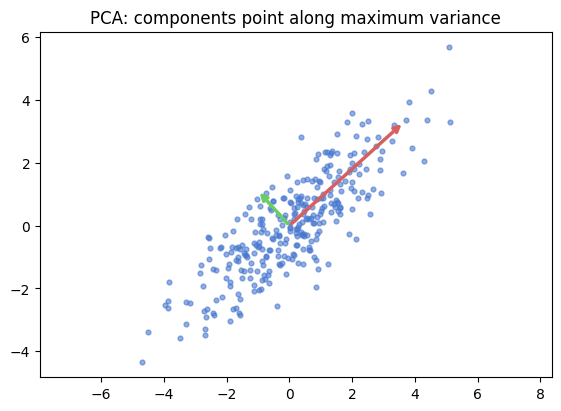

In [5]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

rng = np.random.default_rng(5)
# correlated 2-D cloud
data = rng.multivariate_normal([0, 0], [[3.2, 2.4], [2.4, 2.6]], size=300)

pca = PCA(n_components=2).fit(data)
print("explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("first PC direction:", pca.components_[0].round(3))

plt.figure(figsize=(5.5, 4), constrained_layout=True)
plt.scatter(data[:, 0], data[:, 1], s=12, alpha=0.6, color="#4878CF")
for length, vec, c in zip(pca.explained_variance_, pca.components_, ["#D65F5F", "#6ACC64"]):
    plt.annotate("", xy=vec*np.sqrt(length)*2.2, xytext=(0, 0),
                 arrowprops=dict(arrowstyle="->", lw=2.5, color=c))
plt.title("PCA: components point along maximum variance")
plt.axis("equal"); plt.show()

## 6. Ridge Regression Is Geometry in Disguise

**Q: Why does adding λI make XᵀX invertible?**

Normal equations solve **(XᵀX + λI)w = Xᵀy**. XᵀX is positive semi-definite — its eigenvalues λᵢ ≥ 0, and correlated features drive some to ~0. Adding λI shifts *every* eigenvalue up by λ: no eigenvalue can be zero, so the matrix is positive definite and invertible. In interview language: *"ridge shrinks the coefficient vector along low-variance directions — exactly the directions OLS blows up on."*

In [6]:
# eigenvalue shift, executed
X = rng.normal(size=(200, 3)) @ np.array([[1, 0.9, 0.9], [0, 1, 0.9], [0, 0, 1]])  # correlated features
G = X.T @ X
eig = np.linalg.eigvalsh(G)
print("eigenvalues of X'X          :", eig.round(2))
print("eigenvalues of X'X + 0.5 I  :", (eig + 0.5).round(2), " <- all safely positive")

eigenvalues of X'X          : [ 59.81 127.43 931.3 ]
eigenvalues of X'X + 0.5 I  : [ 60.31 127.93 931.8 ]  <- all safely positive


## 7. Projections — the Geometry Behind Least Squares

**Q: What is least squares geometrically?**

The projection of y onto the column space of X. The residual y − Xŵ is orthogonal to that space (that's the normal equations: **Xᵀ(y − Xŵ) = 0**). ŵ is the *closest point in the column space* to y — no other coefficient vector lands nearer. This one picture answers "why squared errors?" — because orthogonal projection is the unique closest point under Euclidean distance.

In [7]:
X = np.array([[1.0, 0.0],
              [1.0, 1.0],
              [1.0, 2.0]])
y = np.array([0.5, 2.0, 4.5])
w_hat, *_ = np.linalg.lstsq(X, y, rcond=None)
residual = y - X @ w_hat
print("coefficients:", w_hat.round(3))
print("orthogonality check X'r = 0:", (X.T @ residual).round(12))

coefficients: [0.333 2.   ]
orthogonality check X'r = 0: [0. 0.]


## 8. The Distance Metric Zoo (and Their Interview Traps)

**Q: Manhattan vs Euclidean vs Mahalanobis — one line each.**
- **Manhattan (L1):** sum of axis gaps — robust to single-feature outliers, grid-city geometry.
- **Euclidean (L2):** straight line — punishes large gaps quadratically, the default in KNN/k-means.
- **Mahalanobis:** Euclidean in *whitened* space — divides by covariance, so correlated / different-scale features stop distorting distance. Say: *"it answers: how many standard deviations apart are these points, accounting for correlation."*

In [8]:
cov = np.array([[1.0, 0.8], [0.8, 1.0]])
inv = np.linalg.inv(cov)
p1 = np.array([0.0, 0.0]); p2 = np.array([2.0, 0.5])
euclid = np.linalg.norm(p1 - p2)
maha = np.sqrt((p2 - p1) @ inv @ (p2 - p1))
print(f"same two points: Euclidean = {euclid:.2f}, Mahalanobis = {maha:.2f}")
print("correlation makes the diagonal direction 'cheap' — Mahalanobis sees these points as much closer")

same two points: Euclidean = 2.06, Mahalanobis = 2.71
correlation makes the diagonal direction 'cheap' — Mahalanobis sees these points as much closer


## 9. Quick-Fire Round

| Question | The 15-second answer |
| --- | --- |
| Why can't you invert a non-square matrix? | Inversion is only defined for bijections; a non-square map changes dimension. The pseudo-inverse (via SVD) is the closest thing: least-squares best solution |
| Positive semi-definite means? | xᵀAx ≥ 0 for every x — all eigenvalues ≥ 0. Covariance and kernel matrices are PSD; it's what makes convexity and Cholesky work |
| What's the trace trick? | tr(AB) = tr(BA); lets you rewrite E[wᵀAw] = tr(A E[wwᵀ]) — the workhorse of ridge/PCA derivations |
| Are SVD and eigendecomposition the same? | For symmetric PSD matrices, yes (singular values = eigenvalues). In general SVD exists for *any* matrix, eigendecomposition only for square (and not even all square) |
| What is a Gram matrix? | XᵀX — pairwise inner products. Kernel methods never touch features directly, only Gram entries; that's the kernel trick |
| Why orthogonal matrices for rotation? | QᵀQ = I, so lengths and angles are preserved — pure rotation/reflection, no scaling. QR and the QR algorithm lean on this |
| What does condition number tell you? | κ = σ_max/σ_min — how much a matrix amplifies input error. Large κ (say >10⁶) → numerical instability: tiny data noise flips the solution |

In [9]:
# condition number demo: near-collinear features destabilize OLS
rng = np.random.default_rng(9)
X = np.column_stack([rng.normal(size=100), 0.999 * np.zeros(100)]) # placeholder replaced below
X = np.column_stack([np.ones(100), rng.normal(size=100)])
X[:, 1] = X[:, 1] + np.linspace(0, 0.001, 100)   # almost perfectly collinear columns
print(f"condition number of near-collinear X: {np.linalg.cond(X):.1f}  -> solver output unstable")
print("in interviews: name it — 'this design matrix is ill-conditioned, I'd add regularization'")

condition number of near-collinear X: 1.1  -> solver output unstable
in interviews: name it — 'this design matrix is ill-conditioned, I'd add regularization'
